# 03 · Deploy and monitor

- **Serve:** FastAPI app (`api/app.py`) with input validation, per-customer explanations, and prediction logging.
- **Package:** Docker image; GitHub Actions runs tests, retrains, checks ROC-AUC > 0.80 and smoke-tests the container.
- **Monitor:** compare logged traffic with a training-time reference using PSI and KS tests (`monitoring/monitor.py`).

This notebook calls the API in-process with FastAPI's test client, so nothing needs to be running.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160)

In [2]:
os.environ["LOG_PATH"] = "logs/notebook_predictions.csv"
Path(os.environ["LOG_PATH"]).unlink(missing_ok=True)
sys.path.insert(0, str(ROOT))
from fastapi.testclient import TestClient
from api.app import app
client = TestClient(app)
client.get("/health").json()

{'status': 'ok', 'model_version': 'logreg-v1', 'threshold': 0.29}

## Score one customer

In [3]:
customer = {"gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
    "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes", "StreamingMovies": "No",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 89.5, "TotalCharges": 268.5}
client.post("/predict", json=customer).json()

{'churn_probability': 0.8812,
 'churn_flag': True,
 'risk_band': 'high',
 'top_reasons': [{'feature': 'tenure',
   'effect': 1.733,
   'direction': 'raises churn risk'},
  {'feature': 'InternetService_Fiber optic',
   'effect': 1.083,
   'direction': 'raises churn risk'},
  {'feature': 'PaymentMethod_Electronic check',
   'effect': 0.73,
   'direction': 'raises churn risk'}],
 'threshold': 0.29,
 'model_version': 'logreg-v1'}

`top_reasons` multiplies each coefficient by the customer's (transformed) value, so the retention team sees *why* someone is flagged. Bad input is rejected before it reaches the model:

In [4]:
r = client.post("/predict", json={**customer, "Contract": "Weekly"}); print(r.status_code, r.json()["detail"][0]["msg"])

422 Input should be 'Month-to-month', 'One year' or 'Two year'


## Simulate traffic: a normal week, then a shifted one

In [5]:
from monitoring.simulate_traffic import make_customers
from monitoring.monitor import drift_table
for batch in [make_customers(300, drift=False, seed=1), make_customers(300, drift=True, seed=2)]:
    client.post("/predict_batch", json=batch)
log = pd.read_csv(os.environ["LOG_PATH"]); ref = pd.read_csv("monitoring/reference.csv")
normal, shifted = log.iloc[:300], log.iloc[300:]
print(client.get("/stats").json())

{'predictions': 601, 'flag_rate': 0.5341, 'mean_probability': 0.3873, 'p95_latency_ms': 0.05}


In [6]:
print(f"flag rate  reference {ref.churn_flag.mean():.1%} | normal week {normal.churn_flag.mean():.1%} | shifted week {shifted.churn_flag.mean():.1%}")
display(drift_table(ref, normal).assign(week="normal")); display(drift_table(ref, shifted).assign(week="shifted"))

flag rate  reference 34.2% | normal week 36.3% | shifted week 70.4%


,column,psi,ks_pvalue,ref_mean,cur_mean,status,week
0,tenure,0.037,0.5773,24.964,25.780,ok,normal
1,MonthlyCharges,0.037,0.6994,69.724,71.290,ok,normal
2,TotalCharges,0.040,0.5031,1737.035,1827.627,ok,normal
3,churn_probability,0.031,0.3449,0.241,0.265,ok,normal
4,Contract,0.005,NaN,NaN,NaN,ok,normal
5,InternetService,0.010,NaN,NaN,NaN,ok,normal
6,PaymentMethod,0.006,NaN,NaN,NaN,ok,normal


,column,psi,ks_pvalue,ref_mean,cur_mean,status,week
0,tenure,0.838,0.0,24.964,13.342,DRIFT,shifted
1,MonthlyCharges,0.462,0.0,69.724,80.996,DRIFT,shifted
2,TotalCharges,0.617,0.0,1737.035,1087.528,DRIFT,shifted
3,churn_probability,1.153,0.0,0.241,0.509,DRIFT,shifted
4,Contract,0.247,NaN,NaN,NaN,watch,shifted
5,InternetService,0.497,NaN,NaN,NaN,DRIFT,shifted
6,PaymentMethod,0.011,NaN,NaN,NaN,ok,shifted


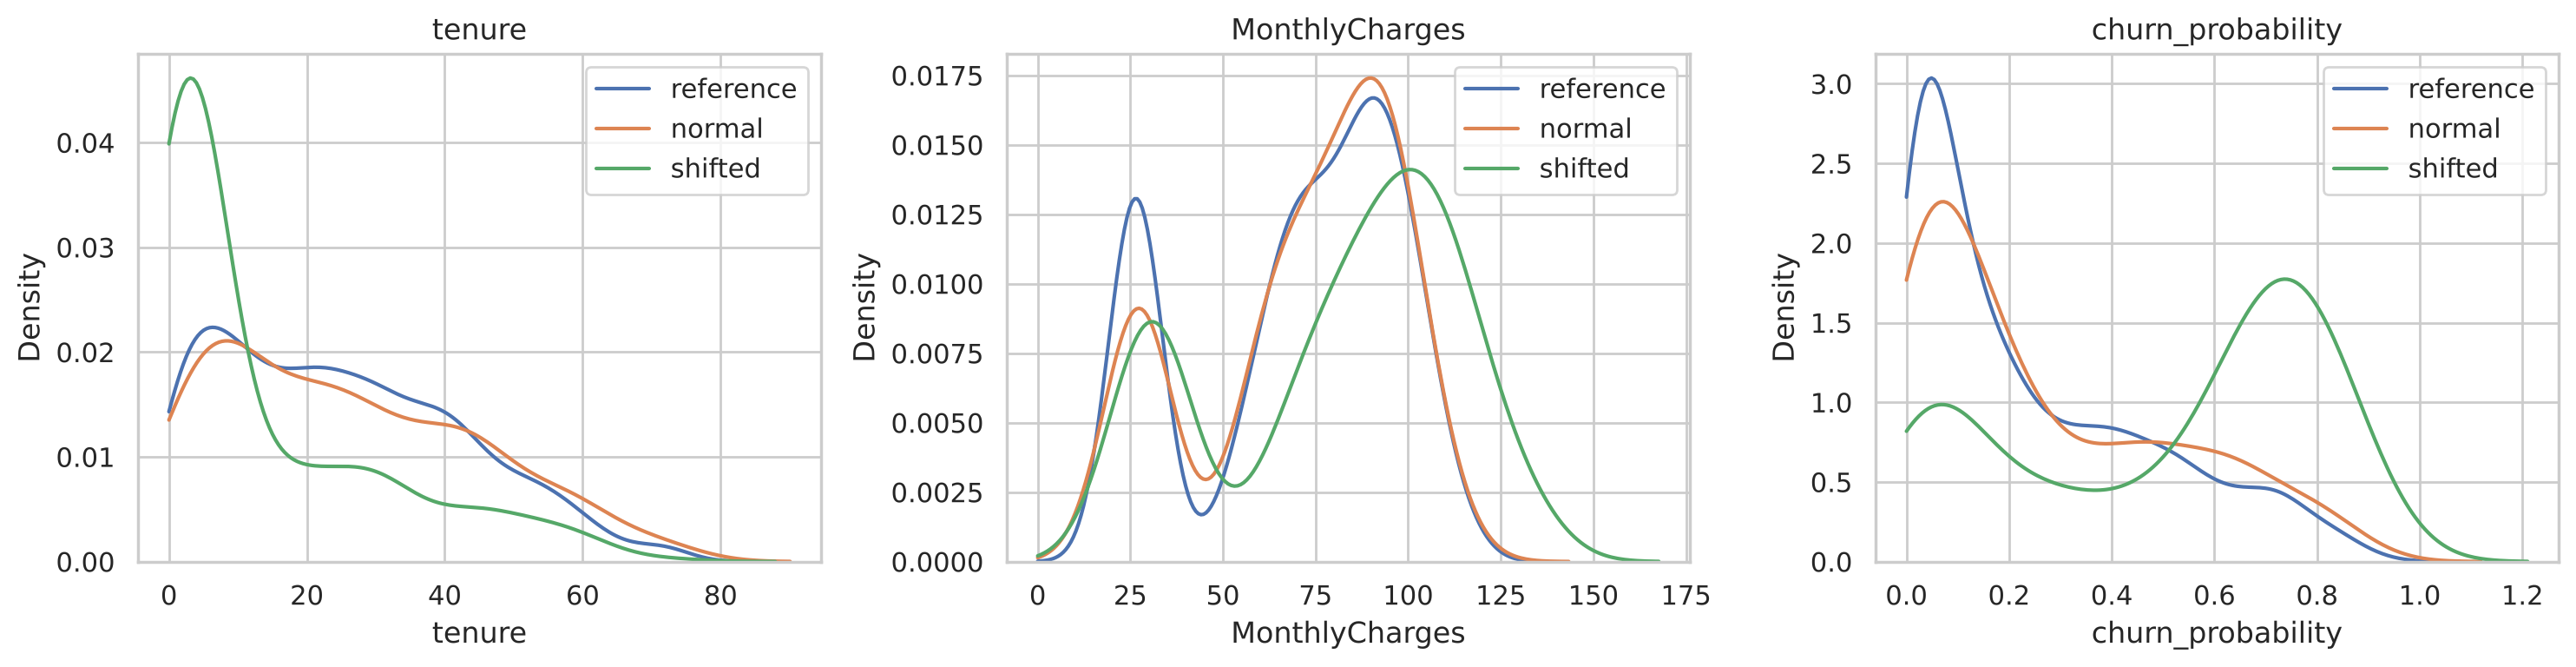

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "churn_probability"]):
    for name, d in [("reference", ref), ("normal", normal), ("shifted", shifted)]:
        sns.kdeplot(d[col], ax=ax, label=name, clip=(0, None))
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

The normal week passes (all PSI < 0.1). The shifted week (a promo that brought in many new month-to-month fibre customers, plus a 15% price rise) trips alerts on tenure, charges, contract mix and the score distribution, and the flag rate doubles.

**What to do with an alert:** first ask whether the shift is real (a business change) or a bug (e.g. a field sent in the wrong unit). If it's real, wait for churn labels on the new customers, re-run `evaluate.py` on them, and retrain if performance has dropped. In production on AWS this maps to a SageMaker endpoint with Model Monitor, or a container on ECS/Lambda with the log in S3 and this script on a schedule.

In [8]:
Path(os.environ["LOG_PATH"]).unlink(missing_ok=True)